# 04 — Precipitation-type skill as a function of near-surface temperature


**Approach.** Every verification case is binned by a **reference** RAP temperature at the mPING location and valid time, and skill is computed within each bin.
- The reference is independent of the forecast system, so all 12 systems share the same x-axis and are compared on identical cases.
- The question being answered is: *at what real-atmosphere temperatures do the forecasts fail?*

**Reference temperature source** (set `TEMP_SOURCE` in Section 2):
- `"rap_2m"` (default): RAP 2-m air temperature, read directly from the RAP 13-km analysis (`awp130pgrb`, F00) at the nearest grid point and valid time.
- `"rap_sfc"`: RAP surface (skin) temperature from the same files.
- `"rap_interp"`: the profile-interpolated RAP column in the mPING parquet (`TEMP_C_0_m`); kept only for comparison.
- `"era5"`: ERA5 2-m temperature at the nearest grid point and hour (sensitivity check).

RAP is the same model used for the mPING QC, so the reference stays consistent with the QC. The RAP fields are downloaded with Herbie (AWS/Google/NOMADS archives) and cached, so the download runs only once. There is no automatic fallback between sources. Section 3 lists the temperature-like columns in the parquet so you can confirm the choice.

**Sample.** The common-valid sample from notebook 01. All 12 systems (EDNN, Bourgouin, native GFS) are verified on identical cases.

**Figures**
1. **Overall accuracy vs temperature** at forecast days 1, 3, 5 and 7, with the observed class mix per temperature bin shown above each panel.
2. **Per-class CSI and POD vs temperature** for a chosen forecast day. This separates "the near-freezing classes are hard" from "every class is harder near freezing".

**Outputs**

| File | Contents |
|---|---|
| `skill_by_reference_temperature.csv` | Accuracy, POD and CSI per system / day / temperature bin / class |
| `accuracy_near_freezing_summary.csv` | Accuracy inside vs outside the near-freezing band, per system and day |
| `accuracy_vs_reference_temperature.pdf` | Figure 1 |
| `csi_pod_vs_reference_temperature.pdf` | Figure 2 |

## 1. Imports

In [1]:
from pathlib import Path
import glob, re
import numpy as np
import pandas as pd
import xarray as xr
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 100)

## 2. Configuration

**Must match notebook 01:** `OBS_RULE`, the mPING path, QC settings and class definitions. These are needed to rebuild `obs_id` exactly (Section 3).

**Temperature settings**
- `TEMP_SOURCE`: `"rap_2m"` (default), `"rap_sfc"`, `"rap_interp"` or `"era5"`.
- `RAP_SAVE_DIR`: where Herbie writes temporary GRIB subsets (scratch).
- `RAP_CACHE`: parquet of the extracted RAP temperature per `obs_id`; delete it to force a re-download.
- `TEMP_COL`: parquet column, used only with `"rap_interp"`.
- `T_LABEL`: x-axis label used in both figures.
- `ERA5_GLOB` / `ERA5_VAR`: used only when `TEMP_SOURCE = "era5"`. The defaults follow the NCAR RDA ERA5 layout; **check them against the files on GLADE**.

**Binning**
- `T_EDGES`: temperature bin edges (°C). Cases outside the range are excluded from the figures, and the number excluded is reported.
- `NEAR_FREEZING`: the band highlighted in the figures and used in the summary table.
- `MIN_N`: minimum number of cases for a value to be plotted.

In [2]:
# ============================================================
# OBSERVED-CLASS RULE (must be identical in notebooks 01–04)
#   "modal":     most-reported ptype; ties broken FZRA > IP > Snow > Rain
#                (same rule as the EDNN training labels); no agreement threshold
#   "consensus": most-reported ptype, kept only with >= CONSENSUS % agreement
# Each rule writes to its own output and figure folders, so cached
# collocations (keyed by obs_id) from the two rules never mix.
# ============================================================
OBS_RULE = "modal"                    # "modal" | "consensus"
CONSENSUS = 70.0                      # used only when OBS_RULE == "consensus"
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"

# ============================================================
# PATHS (must match notebook 01)
# ============================================================
MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
FIG.mkdir(parents=True, exist_ok=True)
COMMON_FILE = OUT / "common_valid_multimodel_predictions.parquet"

# ============================================================
# mPING QC (must match notebook 01 so obs_id can be rebuilt)
# ============================================================
START = pd.Timestamp("2021-12-01 00:00:00")
END = pd.Timestamp("2022-04-01 00:00:00")      # exclusive
LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
PTYPE_COLS = {"sn_percent": "Snow", "ra_percent": "Rain",
              "pl_percent": "Ice Pellet", "fzra_percent": "Freezing Rain"}

# ============================================================
# REFERENCE TEMPERATURE
# ============================================================
TEMP_SOURCE = "rap_2m"        # "rap_2m" | "rap_sfc" | "rap_interp" | "era5"

# RAP GRIB (rap_2m / rap_sfc): 13-km analysis, nearest grid point, via Herbie
RAP_PRODUCT = "awp130pgrb"
RAP_SEARCH = {"rap_2m": ":TMP:2 m above ground:", "rap_sfc": ":TMP:surface:"}
RAP_SAVE_DIR = Path("/glade/derecho/scratch/sakor/herbie")
RAP_CACHE = OUT / f"{TEMP_SOURCE}_at_mping.parquet"
RAP_MAX_DIST_KM = 15.0        # nearest grid point must be within this distance

TEMP_COL = "TEMP_C_0_m"       # used only for "rap_interp"
T_LABELS = {"rap_2m": "RAP 2-m temperature (°C)",
            "rap_sfc": "RAP surface temperature (°C)",
            "rap_interp": "RAP interpolated 0-m temperature (°C)",
            "era5": "ERA5 2-m temperature (°C)"}
T_LABEL = T_LABELS[TEMP_SOURCE]

ERA5_GLOB = ("/glade/campaign/collections/rda/data/d633000/e5.oper.an.sfc/{ym}/"
             "e5.oper.an.sfc.128_167_2t.ll025sc.*.nc")
ERA5_VAR = "VAR_2T"           # Kelvin

# ============================================================
# CLASSES AND SYSTEMS
# ============================================================
CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
CLASS_COLORS = {"Rain": "#009E73", "Snow": "#56B4E9",
                "Ice Pellet": "#CC79A7", "Freezing Rain": "#D55E00"}

SYSTEM_ORDER = [
    "Aurora — EDNN", "Aurora — Bourgouin",
    "GraphCast — EDNN", "GraphCast — Bourgouin",
    "WXFormer — EDNN", "WXFormer — Bourgouin",
    "FuXi — EDNN", "FuXi — Bourgouin",
    "Pangu-Weather — EDNN", "Pangu-Weather — Bourgouin",
    "GFS — Native", "GFS — EDNN",
]
MODEL_ORDER = list(dict.fromkeys(s.split(" — ")[0] for s in SYSTEM_ORDER))
MODEL_COLORS = {"Aurora": "#0072B2", "GraphCast": "#E69F00", "WXFormer": "#009E73",
                "FuXi": "#CC79A7", "Pangu-Weather": "#D55E00", "GFS": "#000000"}
METHOD_LS = {"EDNN": "-", "Bourgouin": "--", "Native": "--"}

# ============================================================
# BINNING
# ============================================================
T_EDGES = np.arange(-12, 12.01, 1.0)       # °C
T_CENT = 0.5 * (T_EDGES[:-1] + T_EDGES[1:])
NEAR_FREEZING = (0.0, 4.0)                 # °C, highlighted band
MIN_N = 30
FIG1_DAYS = [1, 3, 5, 7]
FIG2_DAY = 1

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5,
    "axes.titlesize": 8.5, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
LETTERS = "abcdefghijklmnop"

## 3. Rebuild the mPING observation table and choose the temperature source

Notebook 01 assigned `obs_id` as the row number after QC filtering. This cell repeats exactly the same filtering (plus any temperature column) and then **checks** that every `obs_id` in the common sample has the same time, latitude and longitude. If the check fails, the QC settings above don't match notebook 01.

The temperature-like columns found in the mPING file are printed for reference. With `TEMP_SOURCE = "rap_interp"`, the notebook requires `TEMP_COL` to be present and stops otherwise.

In [3]:
schema_cols = pq.read_schema(MPING_PATH).names
candidates = [c for c in schema_cols if re.search(r"(temp|t2m|^2t$|t_2m)", c, re.I)]
print(f"Temperature-like columns in mPING file ({len(candidates)}):")
print(candidates[:40], "..." if len(candidates) > 40 else "")

if TEMP_SOURCE not in T_LABELS:
    raise ValueError(f"unknown TEMP_SOURCE {TEMP_SOURCE!r}")
if TEMP_SOURCE == "rap_interp" and TEMP_COL not in schema_cols:
    raise ValueError(f"column {TEMP_COL!r} not in {MPING_PATH}")
USE_SOURCE = TEMP_SOURCE
print(f"\n→ Reference temperature source: {USE_SOURCE} — {T_LABEL}")

def assign_obs_class(d):
    """Observed class from the mPING class percentages, following OBS_RULE.

    The class is the most-reported ptype. idxmax returns the FIRST column at the
    maximum, so ordering the columns by TIE_PRIORITY breaks ties as
    FZRA > IP > Snow > Rain. Percentages are rounded only for tie detection;
    the consensus threshold uses the unrounded values.
    """
    raw = d[TIE_PRIORITY].astype(float).fillna(0.0)
    if raw.to_numpy().max() <= 1.0:              # stored as fractions
        raw = raw * 100.0
    pct = raw.round(6)
    d = d.copy()
    d["obs_consensus"] = raw.max(axis=1)
    d["obs_tie_resolved"] = pct.eq(pct.max(axis=1), axis=0).sum(axis=1) > 1
    d["obs_class"] = pct.idxmax(axis=1).map(PTYPE_COLS)
    if OBS_RULE == "consensus":
        keep = d.obs_consensus >= CONSENSUS
    elif OBS_RULE == "modal":
        keep = d.obs_consensus > 0               # any reported ptype
    else:
        raise ValueError(f"unknown OBS_RULE {OBS_RULE!r}")
    return d[keep]

def prepare_mping(path, extra_cols=()):
    """Identical filtering to notebook 01, so obs_id matches."""
    cols = ["datetime", "lat", "lon"] + list(PTYPE_COLS) + list(extra_cols)
    d = pd.read_parquet(path, columns=cols)
    d["datetime"] = pd.to_datetime(d["datetime"])
    d = d[(d.datetime >= START) & (d.datetime < END)].copy()
    d = d[d.datetime.dt.hour.isin([0, 6, 12, 18])].copy()
    d = d[d.lat.between(LAT_MIN, LAT_MAX) & d.lon.between(LON_MIN, LON_MAX)].copy()
    d = assign_obs_class(d).reset_index(drop=True)
    d["obs_id"] = np.arange(len(d), dtype=np.int64)
    return d[["obs_id", "datetime", "lat", "lon"] + list(extra_cols)]

obs = prepare_mping(MPING_PATH, extra_cols=[TEMP_COL] if USE_SOURCE == "rap_interp" else [])

common = pd.read_parquet(COMMON_FILE)
ref = common[["obs_id", "datetime", "lat", "lon"]].drop_duplicates("obs_id")
chk = ref.merge(obs, on="obs_id", suffixes=("_c", "_m"), how="left")
ok = ((chk.datetime_c == chk.datetime_m)
      & np.isclose(chk.lat_c, chk.lat_m) & np.isclose(chk.lon_c, chk.lon_m))
assert ok.all(), f"{(~ok).sum()} obs_id mismatches — QC settings or OBS_RULE differ from notebook 01"
print(f"obs_id check passed for {len(ref):,} observations")

Temperature-like columns in mPING file (71):
['TEMP_C_0_m', 'TEMP_C_250_m', 'TEMP_C_500_m', 'TEMP_C_750_m', 'TEMP_C_1000_m', 'TEMP_C_1250_m', 'TEMP_C_1500_m', 'TEMP_C_1750_m', 'TEMP_C_2000_m', 'TEMP_C_2250_m', 'TEMP_C_2500_m', 'TEMP_C_2750_m', 'TEMP_C_3000_m', 'TEMP_C_3250_m', 'TEMP_C_3500_m', 'TEMP_C_3750_m', 'TEMP_C_4000_m', 'TEMP_C_4250_m', 'TEMP_C_4500_m', 'TEMP_C_4750_m', 'TEMP_C_5000_m', 'TEMP_C_5250_m', 'TEMP_C_5500_m', 'TEMP_C_5750_m', 'TEMP_C_6000_m', 'TEMP_C_6250_m', 'TEMP_C_6500_m', 'TEMP_C_6750_m', 'TEMP_C_7000_m', 'TEMP_C_7250_m', 'TEMP_C_7500_m', 'TEMP_C_7750_m', 'TEMP_C_8000_m', 'TEMP_C_8250_m', 'TEMP_C_8500_m', 'TEMP_C_8750_m', 'TEMP_C_9000_m', 'TEMP_C_9250_m', 'TEMP_C_9500_m', 'TEMP_C_9750_m'] ...

→ Reference temperature source: rap_2m — RAP 2-m temperature (°C)
obs_id check passed for 30,856 observations


## 4. Reference temperature at each observation

- **RAP GRIB sources (`rap_2m`, `rap_sfc`):** for each valid time, only the requested field is downloaded from the RAP 13-km analysis (F00) with Herbie, and the value at the **nearest grid point** is taken (no spatial interpolation). Results are cached in `RAP_CACHE`. Valid times that can't be retrieved are listed and left as NaN.
- **`rap_interp`:** the parquet column is used directly (converted from K if needed).
- **ERA5 source:** 2-m temperature is taken from the nearest grid point and hour, one month of files at a time. The cell checks that every matched ERA5 time equals the report's valid time.

The temperature is computed once per observation (about 30k) and then attached to every system and forecast day.

In [4]:
def era5_t2m_at_obs(o):
    """ERA5 2-m temperature (°C) at the nearest grid point and hour, one month at a time.
    Each month is subset to the CONUS box and the needed hours before loading (no dask needed)."""
    out = pd.Series(np.nan, index=o.index, dtype=float)
    for ym, g in o.groupby(o.datetime.dt.strftime("%Y%m")):
        files = sorted(glob.glob(ERA5_GLOB.format(ym=ym)))
        if not files:
            raise FileNotFoundError(f"No ERA5 files for {ym}: {ERA5_GLOB.format(ym=ym)}")
        parts = []
        for f in files:
            with xr.open_dataset(f) as ds:
                da = ds[ERA5_VAR]
                to360 = float(da.longitude.max()) > 180
                lon0, lon1 = (LON_MIN % 360, LON_MAX % 360) if to360 else (LON_MIN, LON_MAX)
                lat_sl = (slice(LAT_MAX + 1, LAT_MIN - 1) if da.latitude[0] > da.latitude[-1]
                          else slice(LAT_MIN - 1, LAT_MAX + 1))
                sub = da.sel(latitude=lat_sl, longitude=slice(lon0 - 1, lon1 + 1))
                sub = sub.sel(time=sub.time[sub.time.isin(g.datetime.unique())])
                if sub.sizes["time"]:
                    parts.append(sub.load())
        da = xr.concat(parts, dim="time").sortby("time")
        lon = np.mod(g.lon.to_numpy(), 360.0) if to360 else g.lon.to_numpy()
        v = da.sel(time=xr.DataArray(g.datetime.to_numpy(), dims="obs"),
                   latitude=xr.DataArray(g.lat.to_numpy(), dims="obs"),
                   longitude=xr.DataArray(lon, dims="obs"),
                   method="nearest")
        assert (pd.to_datetime(v.time.values) == g.datetime.to_numpy()).all(), \
            f"ERA5 time mismatch in {ym} (hour missing from files?)"
        out.loc[g.index] = v.values - 273.15
        print(f"  ERA5 {ym}: {len(g):,} obs")
    return out

def _xyz(lat, lon):
    lat, lon = np.radians(lat), np.radians(lon)
    return np.c_[np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)]

def rap_grib_at_obs(o, source):
    """RAP temperature (°C) at the nearest grid point of the RAP 13-km analysis.
    One Herbie request per valid time; only the requested GRIB message is downloaded."""
    from herbie import Herbie
    from scipy.spatial import cKDTree

    if RAP_CACHE.exists():
        cached = pd.read_parquet(RAP_CACHE)
        if set(o.obs_id) <= set(cached.obs_id):
            print(f"Using cached {source} from {RAP_CACHE.name}")
            return o[["obs_id"]].merge(cached, on="obs_id", how="left")["T_rap"].to_numpy()

    RAP_SAVE_DIR.mkdir(parents=True, exist_ok=True)
    out = pd.Series(np.nan, index=o.index, dtype=float)
    tree, grid_shape, failed = None, None, []
    for k, (t, g) in enumerate(o.groupby("datetime")):
        try:
            H = Herbie(t, model="rap", product=RAP_PRODUCT, fxx=0,
                       save_dir=RAP_SAVE_DIR, verbose=False)
            ds = H.xarray(RAP_SEARCH[source], remove_grib=True)
            da = ds[list(ds.data_vars)[0]]
            if tree is None or da.shape != grid_shape:     # grid is fixed; build once
                glat = da.latitude.values.ravel()
                glon = ((da.longitude.values.ravel() + 180) % 360) - 180
                tree, grid_shape = cKDTree(_xyz(glat, glon)), da.shape
                dist, idx_all = tree.query(_xyz(o.lat.to_numpy(), o.lon.to_numpy()))
                dist_km = 2 * 6371.0 * np.arcsin(np.clip(dist / 2, 0, 1))
                print(f"Nearest RAP grid point: median {np.median(dist_km):.1f} km, "
                      f"max {dist_km.max():.1f} km")
                assert dist_km.max() < RAP_MAX_DIST_KM, "mPING report outside RAP grid?"
                nn = pd.Series(idx_all, index=o.index)
            out.loc[g.index] = da.values.ravel()[nn.loc[g.index].to_numpy()] - 273.15
        except Exception as e:
            failed.append((t, str(e)[:80]))
        if k % 50 == 0:
            print(f"  {t:%Y-%m-%d %H} UTC ({k + 1} valid times)")

    if failed:
        print(f"[warn] {len(failed)} valid times not retrieved:")
        for t, e in failed[:10]:
            print(f"   {t}: {e}")
    pd.DataFrame({"obs_id": o.obs_id.to_numpy(), "T_rap": out.to_numpy()}).to_parquet(RAP_CACHE)
    print(f"Saved {RAP_CACHE}")
    return out.to_numpy()

if USE_SOURCE in ("rap_2m", "rap_sfc"):
    obs["T_ref"] = rap_grib_at_obs(obs, USE_SOURCE)
elif USE_SOURCE == "rap_interp":
    t = obs[TEMP_COL].astype(float)
    if t.median() > 200:
        t = t - 273.15
        print("Converted RAP temperature from K to °C")
    obs["T_ref"] = t
else:
    obs["T_ref"] = era5_t2m_at_obs(obs)

print(f"\nMissing reference temperature: {obs.T_ref.isna().sum():,} of {len(obs):,}")
print("\nReference temperature (°C) by observed class:")
cls_map = common.drop_duplicates("obs_id").set_index("obs_id").obs_class
display(obs.assign(obs_class=obs.obs_id.map(cls_map))
           .groupby("obs_class").T_ref.describe(percentiles=[.05, .5, .95])
           .reindex(CLASS_ORDER).round(2))

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Using cached rap_2m from rap_2m_at_mping.parquet

Missing reference temperature: 0 of 30,856

Reference temperature (°C) by observed class:


,count,mean,std,min,5%,50%,95%,max
obs_class,,,,,,,,
Rain,11932.0,9.53,6.47,-7.64,0.62,8.83,20.64,31.45
Snow,16116.0,-2.99,4.28,-24.99,-10.79,-2.21,2.50,9.44
Ice Pellet,1772.0,-1.84,3.25,-13.73,-7.99,-1.71,3.00,12.44
Freezing Rain,1036.0,-1.41,2.33,-11.09,-5.75,-0.79,0.88,20.04


## 5. Attach temperature and assign bins

This attaches `T_ref` to every row of the common sample and assigns a temperature bin. Cases outside `T_EDGES` (or with no temperature) are excluded from the binned statistics; the number excluded is printed.

In [5]:
common = common.merge(obs[["obs_id", "T_ref"]], on="obs_id", how="left")
common["T_bin"] = pd.cut(common.T_ref, T_EDGES, labels=False, include_lowest=True)

n_obs_total = common.obs_id.nunique()
n_obs_in = common.loc[common.T_bin.notna(), "obs_id"].nunique()
print(f"Observations inside {T_EDGES[0]:.0f} to {T_EDGES[-1]:.0f} °C: "
      f"{n_obs_in:,} of {n_obs_total:,} ({n_obs_in / n_obs_total:.1%})")

binned = common[common.T_bin.notna()].copy()
binned["T_bin"] = binned.T_bin.astype(int)

Observations inside -12 to 12 °C: 26,008 of 30,856 (84.3%)


## 6. Skill per temperature bin

For each system, forecast day and temperature bin:
- **Accuracy:** fraction of cases with the correct class (multiclass).
- **Per-class POD and CSI:** one-vs-rest, as in notebook 01. Native GFS −1 counts as a miss, as in notebooks 01 and 02.

`n_obs` is the number of observed cases of the class in the bin. Both POD and CSI are masked when `n_obs < MIN_N`, because a class that is essentially not observed in a bin (e.g. rain at −8 °C) would otherwise show CSI = 0 from false alarms alone.

In [6]:
rows = []
for (system, day, b), g in binned.groupby(["System", "forecast_day", "T_bin"]):
    o, p = g.obs_code.to_numpy(), g.pred_code.to_numpy()
    base = {"System": system, "Model": system.split(" — ")[0], "Method": system.split(" — ")[1],
            "forecast_day": day, "T_bin": b, "T_center": T_CENT[b],
            "N": len(g), "accuracy": (o == p).mean()}
    for c, name in CLASS_NAMES.items():
        tp = int(((o == c) & (p == c)).sum())
        fn = int(((o == c) & (p != c)).sum())
        fp = int(((o != c) & (p == c)).sum())
        rows.append({**base, "Class": name, "n_obs": tp + fn, "TP": tp, "FN": fn, "FP": fp,
                     "POD": tp / (tp + fn) if (tp + fn) >= MIN_N else np.nan,
                     "CSI": tp / (tp + fn + fp) if (tp + fn) >= MIN_N else np.nan})
tskill = pd.DataFrame(rows)
tskill.loc[tskill.N < MIN_N, "accuracy"] = np.nan
tskill.to_csv(OUT / "skill_by_reference_temperature.csv", index=False)

# accuracy inside vs outside the near-freezing band
lo, hi = NEAR_FREEZING
binned["near_freezing"] = binned.T_ref.between(lo, hi)
summ = (binned.assign(correct=binned.obs_code == binned.pred_code)
        .groupby(["System", "forecast_day", "near_freezing"]).correct.mean()
        .unstack("near_freezing")
        .rename(columns={True: f"acc {lo:g}–{hi:g} °C", False: "acc elsewhere"}))
summ["Δ (band − elsewhere)"] = summ.iloc[:, 1] - summ.iloc[:, 0]
summ = summ.reindex(pd.MultiIndex.from_product([SYSTEM_ORDER, range(1, 8)],
                                               names=["System", "forecast_day"]))
summ.to_csv(OUT / "accuracy_near_freezing_summary.csv")
display(summ.xs(1, level="forecast_day").round(3))

near_freezing,acc elsewhere,acc 0–4 °C,Δ (band − elsewhere)
System,,,
Aurora — EDNN,0.900,0.775,-0.126
Aurora — Bourgouin,0.889,0.670,-0.219
GraphCast — EDNN,0.895,0.774,-0.121
GraphCast — Bourgouin,0.890,0.677,-0.213
WXFormer — EDNN,0.886,0.747,-0.139
WXFormer — Bourgouin,0.885,0.647,-0.238
FuXi — EDNN,0.888,0.758,-0.130
FuXi — Bourgouin,0.894,0.660,-0.233
Pangu-Weather — EDNN,0.895,0.764,-0.132


## 7. Figure 1 — overall accuracy vs reference temperature

**Layout**
- Columns: forecast days set by `FIG1_DAYS` (default 1, 3, 5, 7).
- **Top strip:** number of observed cases per temperature bin, stacked by observed class. This shows where ice pellets and freezing rain occur.
- **Main panel:** fraction correct per bin. Colour is the weather model; **solid = EDNN**, **dashed = Bourgouin / native GFS**.
- The shaded band is the near-freezing range; the dotted line marks 0 °C.


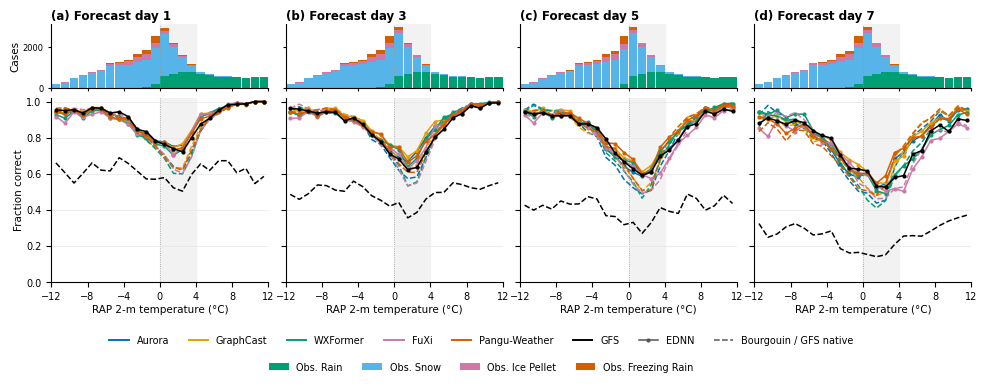

In [7]:
def style(ax):
    ax.axvspan(*NEAR_FREEZING, color="#f2f2f2", zorder=0)
    ax.axvline(0, color="#999999", lw=0.6, ls=":", zorder=1)
    ax.set_xlim(T_EDGES[0], T_EDGES[-1])
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

fig = plt.figure(figsize=(10.0, 3.8))
gs = GridSpec(2, len(FIG1_DAYS), height_ratios=[0.35, 1], hspace=0.08, wspace=0.08,
              left=0.07, right=0.99, top=0.93, bottom=0.25)

for c, day in enumerate(FIG1_DAYS):
    # ---- class-mix strip ----
    axh = fig.add_subplot(gs[0, c])
    g = binned[(binned.System == SYSTEM_ORDER[0]) & (binned.forecast_day == day)]
    counts = (g.groupby(["T_bin", "obs_class"]).size().unstack(fill_value=0)
               .reindex(index=range(len(T_CENT)), columns=CLASS_ORDER, fill_value=0))
    bottom = np.zeros(len(T_CENT))
    for cls in CLASS_ORDER:
        axh.bar(T_CENT, counts[cls], width=0.95, bottom=bottom,
                color=CLASS_COLORS[cls], linewidth=0)
        bottom += counts[cls].to_numpy()
    style(axh)
    axh.tick_params(labelbottom=False)
    axh.tick_params(length=2, labelsize=6)
    axh.set_title(f"({LETTERS[c]}) Forecast day {day}", loc="left", fontweight="bold", pad=3)
    if c == 0:
        axh.set_ylabel("Cases", labelpad=2)
    else:
        axh.tick_params(labelleft=False)
    axh.set_ylim(0, None)

    # ---- accuracy ----
    ax = fig.add_subplot(gs[1, c], sharex=axh)
    for system in SYSTEM_ORDER:
        model, method = system.split(" — ")
        s = (tskill[(tskill.System == system) & (tskill.forecast_day == day)]
             .drop_duplicates("T_bin").set_index("T_bin").reindex(range(len(T_CENT))))
        ax.plot(T_CENT, s.accuracy, color=MODEL_COLORS[model], ls=METHOD_LS[method],
                lw=1.1, marker="o" if method == "EDNN" else None, ms=2)
    style(ax)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(T_EDGES[0], T_EDGES[-1] + 0.1, 4))
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.5)
    ax.set_xlabel(T_LABEL, labelpad=2)
    if c == 0:
        ax.set_ylabel("Fraction correct", labelpad=2)
    else:
        ax.tick_params(labelleft=False)

# share the strip y-limits across panels
ymax = max(a.get_ylim()[1] for a in fig.axes[0::2])
for a in fig.axes[0::2]:
    a.set_ylim(0, ymax)

h_model = [Line2D([], [], color=MODEL_COLORS[m], lw=1.4, label=m) for m in MODEL_ORDER]
h_meth = [Line2D([], [], color="#555555", ls="-", marker="o", ms=2, lw=1.1, label="EDNN"),
          Line2D([], [], color="#555555", ls="--", lw=1.1, label="Bourgouin / GFS native")]
h_cls = [Patch(facecolor=CLASS_COLORS[k], label=f"Obs. {k}") for k in CLASS_ORDER]
fig.legend(handles=h_model + h_meth, loc="lower center", ncol=8, frameon=False,
           fontsize=7, bbox_to_anchor=(0.5, 0.06))
fig.legend(handles=h_cls, loc="lower center", ncol=4, frameon=False,
           fontsize=7, bbox_to_anchor=(0.5, -0.01))
# fig.text(0.5, -0.05, f"Shading: {NEAR_FREEZING[0]:g}–{NEAR_FREEZING[1]:g} °C. "
#          f"Bins with N < {MIN_N} masked. Top strips: observed cases per bin.",
#          ha="center", fontsize=6.5, color="#444444")
fig.savefig(FIG / "accuracy_vs_reference_temperature.pdf", dpi=400, bbox_inches="tight")
plt.show()

## 8. Figure 2 — per-class CSI and POD vs reference temperature

**Layout**
- One forecast day (`FIG2_DAY`, default day 1). Change it to compare leads.
- Rows: CSI and POD. Columns: observed class.
- Line styles as in Figure 1. Values are masked where the class has too few cases in a bin.

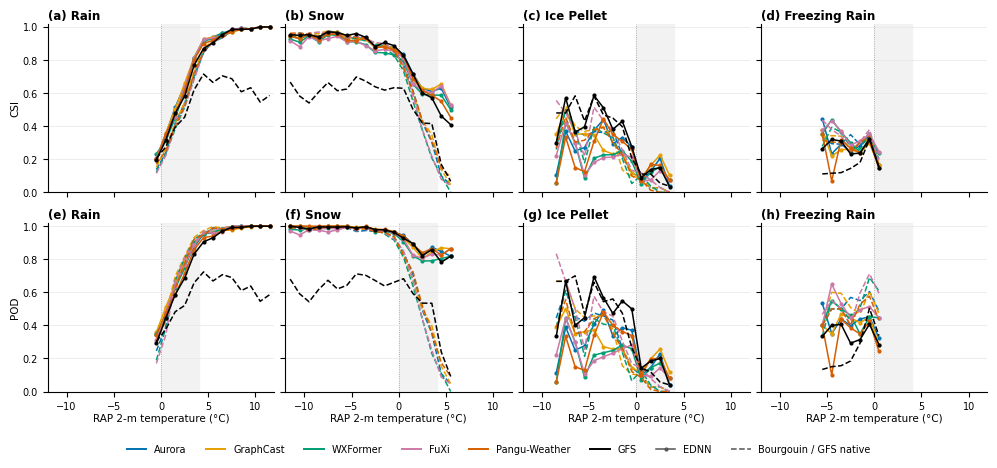

In [8]:
fig, axes = plt.subplots(2, len(CLASS_ORDER), figsize=(10.0, 4.6), sharex=True, sharey=True)
for r, metric in enumerate(["CSI", "POD"]):
    for c, cls in enumerate(CLASS_ORDER):
        ax = axes[r, c]
        for system in SYSTEM_ORDER:
            model, method = system.split(" — ")
            s = (tskill[(tskill.System == system) & (tskill.forecast_day == FIG2_DAY)
                        & (tskill.Class == cls)]
                 .set_index("T_bin").reindex(range(len(T_CENT))))
            ax.plot(T_CENT, s[metric], color=MODEL_COLORS[model], ls=METHOD_LS[method],
                    lw=1.1, marker="o" if method == "EDNN" else None, ms=2)
        style(ax)
        ax.set_ylim(0, 1.02)
        ax.grid(axis="y", color="#e6e6e6", linewidth=0.5)
        ax.set_title(f"({LETTERS[r * len(CLASS_ORDER) + c]}) {cls}", loc="left",
                     fontweight="bold", pad=3)
        if r == 1:
            ax.set_xlabel(T_LABEL, labelpad=2)
        if c == 0:
            ax.set_ylabel(metric, labelpad=2)

h_model = [Line2D([], [], color=MODEL_COLORS[m], lw=1.4, label=m) for m in MODEL_ORDER]
fig.legend(handles=h_model + h_meth, loc="lower center", ncol=8, frameon=False,
           fontsize=7, bbox_to_anchor=(0.5, -0.01))
# fig.text(0.5, -0.045, f"Forecast day {FIG2_DAY}. Shading: {NEAR_FREEZING[0]:g}–{NEAR_FREEZING[1]:g} °C. "
#          f"Values with fewer than {MIN_N} cases masked.",
#          ha="center", fontsize=6.5, color="#444444")
fig.tight_layout(rect=(0, 0.05, 1, 1), w_pad=0.6, h_pad=1.0)
fig.savefig(FIG / f"csi_pod_vs_reference_temperature_day{FIG2_DAY}.pdf", dpi=400, bbox_inches="tight")
plt.show()